# Seminar 3 — Zipf's law on English and Spanish CS theses

**Author:** Profir Alexandru · **Date:** 2026-11-06

Goal: obtain the Zipf's law representation (rank–frequency table, log–log plot, fitted exponent) for an English and a Spanish corpus from the same domain (malicious URL detection) and compare them. The results then go in the seminar docx table, where they are compared with colleagues' corpora from other domains and languages.

## Corpora

| # | Language | Title | Author / Source | Raw words* |
|---|----------|-------|-----------------|-----------|
| A | English | *NURLP: Detection of malicious URLs using NLP and Deep Learning techniques* (Diploma thesis, 2025) | Profir Alexandru. Babeș-Bolyai University Cluj-Napoca, Faculty of Mathematics and Computer Science. Supervisor: Assist. PhD. Briciu Anamaria | 22,866 |
| B | Spanish | *Detección de URLs maliciosas por medio de técnicas de aprendizaje automático* (Master's thesis, 2021) | María Martha Céspedes Maestre. Universidad Nacional de Colombia, Facultad de Ingeniería, Bogotá. Director: Ph.D. Octavio José Salcedo Parra. Codirector: MSc. Carlos Alberto Salazar Herrera. Institutional repository of UNAL | 29,728 |

\* `pdftotext file.pdf - | wc -w`, before cleaning.

In [1]:
import re
import subprocess
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy

BASE = Path.home() / "uni/ACL/seminars/seminar-3"
CORPUS_DIR = BASE / "corpus"
PLOTS_DIR = BASE / "plots"
PLOTS_DIR.mkdir(exist_ok=True)

# start/end: line indices of the body (Introduction .. Bibliography), found in cell 6
CORPORA = {
    "en": {"pdf": CORPUS_DIR / "NURLP-Diploma_Thesis-Profir_Alexandru.pdf",
           "model": "en_core_web_sm", "start": 178, "end": 4438},
    "es": {"pdf": CORPUS_DIR / "1094269813.2021.pdf",
           "model": "es_core_news_sm", "start": 259, "end": 4027},
}

sns.set_theme()

## Step 1 — Text extraction

Text is extracted with the `pdftotext` command-line tool (poppler-utils). It is already installed, so no Python PDF library is needed. Plain mode (no `-layout`) keeps the reading order, so words are not split across columns.

In [2]:
def extract(pdf: Path) -> list[str]:
    out = subprocess.run(["pdftotext", str(pdf), "-"],
                         capture_output=True, text=True, check=True)
    return out.stdout.splitlines()

lines = {lang: extract(c["pdf"]) for lang, c in CORPORA.items()}
for lang, ls in lines.items():
    print(f"{lang}: {len(ls):,} lines")

en: 4,805 lines
es: 4,361 lines


In [3]:
# Exploration: locate the chapter headings to choose start/end for CORPORA
HEADINGS = {
    "en": r"(Introduction|Conclusions|Bibliography)$",
    "es": r"(Introducción|Conclusiones.*|Bibliografía)$",
}
for lang, ls in lines.items():
    print(f"--- {lang}")
    for i, l in enumerate(ls):
        if re.match(HEADINGS[lang], l.strip()):
            print(i, l)

--- en
63 Introduction
160 Conclusions
170 Bibliography
178 Introduction
4348 Conclusions
4438 Bibliography
--- es
208 Conclusiones y recomendaciones ........................................................................................... 83
210 Conclusiones ........................................................................................................................................ 83
259 Introducción
288 Introducción
321 Introducción
360 Introducción
3973 Conclusiones y recomendaciones
4015 Conclusiones y recomendaciones
4027 Bibliografía
4054 Bibliografía
4101 Bibliografía
4163 Bibliografía
4225 Bibliografía
4261 Bibliografía
4317 Bibliografía
4354 Bibliografía


## Step 2 — Cleaning rules

- Keep only the body, from the Introduction up to the Bibliography: no title page, abstract, table of contents, bibliography or appendices.
- Drop running headers and footers: any line that repeats 4 or more times in the body, plus the English `CHAPTER n. ...` headers. This also removes bullet-symbol lines (`o`, `§`) in the Spanish text.
- Drop lines that contain only a number (page numbers).
- Remove URLs and email addresses. The theses are about URLs, so many URLs appear in the text; they are data, not words.
- Numbers and punctuation are removed later, at the token level.
- Known limit: text inside tables, figure captions and code listings still gets through.

In [4]:
def clean(lines: list[str], start: int, end: int) -> tuple[str, int]:
    body = lines[start:end]
    repeated = {l for l, c in Counter(l.strip() for l in body).items() if c >= 4 and l}
    kept = [
        l for l in body
        if l.strip() not in repeated
        and not l.strip().isdigit()
        and not re.match(r"CHAPTER \d+\.", l.strip())
    ]
    text = re.sub(r"https?://\S+|www\.\S+|\S+@\S+", " ", "\n".join(kept))
    return text, len(body) - len(kept)

texts = {}
for lang, c in CORPORA.items():
    texts[lang], dropped = clean(lines[lang], c["start"], c["end"])
    print(f"=== {lang}: {dropped} lines dropped, {len(texts[lang]):,} chars")
    print(texts[lang][:500], "\n")

=== en: 724 lines dropped, 132,463 chars
Introduction
Convenient access to various content, services, or applications would not be possible
without Uniform Resource Locators (URLs), which allow us to essentially route any
computer to another resource on the Internet. However, as the distribution of resources
increases, so does their exploitation in the cyber threat sphere, which imposes significant
risks in hostile activities such as malware distribution, phishing & fraud, or data
breaches.
In this context, a series of approaches were  

=== es: 494 lines dropped, 161,832 chars
Los ciberataques representan una gran amenaza para todos los sistemas o activos que
componen una organización. Cada día las organizaciones invierten en mecanismos que sean
capaces de mantener la seguridad de la Información; ya sea para garantizar la disponibilidad
del servicio ofrecido a los clientes o la integridad y confidencialidad de la información que en
ella se maneja. Aun con esto, es utópico creer que un

## Step 3 — Tokens vs types, and tokenization

- A **token** is one occurrence of a word in the text; a **type** is a distinct word form. "the model and the data" has 5 tokens but 4 types, because *the* appears twice. Tokens measure corpus size; types measure vocabulary size.
- A word that appears once (a *hapax legomenon*) is 1 type and 1 token, so the hapax count is the same either way; only the denominator changes.
- After lowercasing, *Model* and *model* are the same type. With lemmas, *model* and *models* also merge, so lemmas give fewer types.

Tokenization: each text goes through the spaCy model for its language (`en_core_web_sm`, `es_core_news_sm`). Only tokens with `token.is_alpha` are kept, meaning letters only (including the Spanish `á é í ó ú ü ñ`). This removes numbers, punctuation and mixed tokens such as `f1` or `http`. All tokens are lowercased.

In [5]:
words, lemmas, stops = {}, {}, {}
for lang, c in CORPORA.items():
    nlp = spacy.load(c["model"], disable=["parser", "ner"])  # lemmatizer kept for step 8
    nlp.max_length = max(nlp.max_length, len(texts[lang]) + 1)
    doc = nlp(texts[lang])
    alpha = [t for t in doc if t.is_alpha]
    words[lang] = [t.lower_ for t in alpha]
    lemmas[lang] = [t.lemma_.lower() for t in alpha]
    stops[lang] = nlp.Defaults.stop_words
    print(f"{lang}: {len(words[lang]):,} tokens, {len(set(words[lang])):,} types, "
          f"{len(stops[lang])} stop words")

en: 17,627 tokens, 2,839 types, 326 stop words
es: 24,218 tokens, 3,161 types, 521 stop words


## Step 4 — Equal size

The Zipf curve, the number of types and the hapax share all grow with corpus size, so the two corpora are only comparable at the same size.

Rule: N = the smaller of the two token counts. Both corpora keep their first N tokens; only the larger one changes.

Both versions are kept: **full** (original size) and **truncated** (size N). The docx table reports the truncated values; the full values are used for the full-vs-truncated comparison.

In [6]:
words_full, lemmas_full = words, lemmas
N = min(len(w) for w in words_full.values())
words_trunc = {lang: w[:N] for lang, w in words_full.items()}
lemmas_trunc = {lang: l[:N] for lang, l in lemmas_full.items()}
assert all(len(w) == N for w in words_trunc.values())

pd.DataFrame({
    "full": {lang: len(w) for lang, w in words_full.items()},
    "truncated (N)": {lang: N for lang in words_full},
    "dropped %": {lang: round(100 * (1 - N / len(w)), 1) for lang, w in words_full.items()},
})

,full,truncated (N),dropped %
en,17627,17627,0.0
es,24218,17627,27.2


## Step 5 — Zipf's law

Count how often each type occurs, then sort the types from most to least frequent: the most frequent gets rank r = 1, the next r = 2, and so on. Zipf's law (G. K. Zipf, 1935/1949) says frequency is roughly inversely proportional to rank:

$$f(r) \approx \frac{C}{r^s}, \quad s \approx 1 \qquad\Rightarrow\qquad r \cdot f(r) \approx C$$

Taking logs gives $\log f = \log C - s \log r$, a straight line with slope $-s$ on a log–log plot.

Expected deviations:
- **Head:** function words (*the, of* / *de, la*) flatten the curve at low ranks (Mandelbrot's correction $f = C/(r+b)^s$).
- **Tail:** many words occur once (hapax legomena), which produces a staircase of equal frequencies.
- **Language:** Spanish morphology (conjugation, gender, number) gives more types and hapaxes for the same N.
- **Domain:** technical terms (*url, features, class* / *urls, modelo*) reach unusually low ranks, close to the top.

In [7]:
counts = {}
for lang in CORPORA:
    counts[(lang, "full")] = Counter(words_full[lang])
    counts[(lang, "trunc")] = Counter(words_trunc[lang])

def rank_table(counts: Counter) -> pd.DataFrame:
    df = pd.DataFrame(counts.most_common(), columns=["word", "f"])
    df.insert(0, "rank", range(1, len(df) + 1))
    df["rel_f"] = df["f"] / df["f"].sum()
    df["r_f"] = df["rank"] * df["f"]
    return df

tables = {key: rank_table(c) for key, c in counts.items()}
for lang in CORPORA:
    print(f"--- {lang} (truncated)")
    display(tables[(lang, "trunc")].head(20))

--- en (truncated)


,rank,word,f,rel_f,r_f
0,1,the,1213,0.068815,1213
1,2,of,596,0.033812,1192
2,3,to,408,0.023146,1224
3,4,and,389,0.022068,1556
4,5,a,371,0.021047,1855
5,6,in,301,0.017076,1806
6,7,or,180,0.010212,1260
7,8,for,176,0.009985,1408
8,9,as,164,0.009304,1476
9,10,url,152,0.008623,1520


--- es (truncated)


,rank,word,f,rel_f,r_f
0,1,de,1527,0.086628,1527
1,2,la,543,0.030805,1086
2,3,que,447,0.025359,1341
3,4,en,443,0.025132,1772
4,5,el,428,0.024281,2140
5,6,y,382,0.021671,2292
6,7,los,367,0.020820,2569
7,8,se,342,0.019402,2736
8,9,un,273,0.015488,2457
9,10,es,234,0.013275,2340


## Step 6 — Fitting s

A straight line is fitted to $\log_{10} f$ against $\log_{10} r$ by least squares. The slope is $-s$, the intercept is $\log_{10} C$, and $R^2$ measures how close the points lie to the line. The fit is done for the top 200 words (the docx graphic) and for all ranks.

In [8]:
def fit_zipf(freqs: list[int]) -> tuple[float, float, float]:
    x = np.log10(np.arange(1, len(freqs) + 1))
    y = np.log10(freqs)
    slope, intercept = np.polyfit(x, y, 1)
    r2 = np.corrcoef(x, y)[0, 1] ** 2
    return -slope, 10**intercept, r2


# self-check on ideal Zipf data
s, C, r2 = fit_zipf([round(1000 / r) for r in range(1, 101)])
assert abs(s - 1) < 0.05 and r2 > 0.99, (s, r2)

fits = {}
for key, c in counts.items():
    freqs = [f for _, f in c.most_common()]
    for scope, top in (("top200", 200), ("all", None)):
        fits[(*key, scope)] = fit_zipf(freqs[:top])

fits_df = pd.DataFrame(fits, index=["s", "C", "R2"]).T.round(3)
fits_df

s         C     R2
en full  top200  0.849  1209.365  0.996
         all     1.032  3138.364  0.966
   trunc top200  0.849  1209.365  0.996
         all     1.032  3138.364  0.966
es full  top200  0.953  2520.164  0.989
         all     1.080  4735.680  0.975
   trunc top200  0.957  1826.800  0.989
         all     1.020  2503.198  0.972

## Step 7 — Plots

- `zipf_top200_en.png`, `zipf_top200_es.png`: the docx graphic. Log–log rank–frequency plot of the 200 most frequent words (truncated corpora), with the fitted line, s and R².
- `zipf_en_es.png`: both corpora, all ranks, with the ideal line $C/r$ (C = frequency of rank 1) for each.

How to read them: points close to the line mean the corpus follows Zipf's law. A flat head and a staircase tail are the expected deviations.

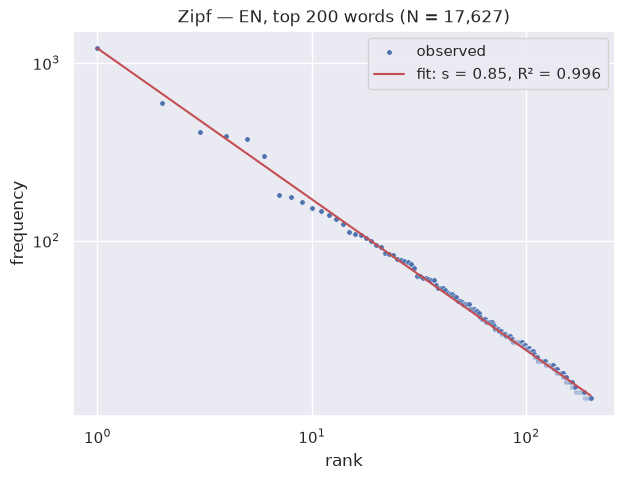

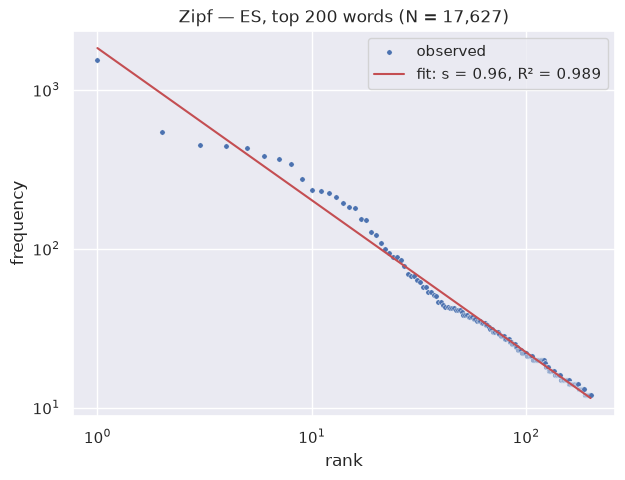

In [9]:
def plot_zipf(counts: Counter, lang: str, top: int = 200):
    freqs = [f for _, f in counts.most_common(top)]
    ranks = np.arange(1, len(freqs) + 1)
    s, C, r2 = fit_zipf(freqs)
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.scatterplot(x=ranks, y=freqs, s=15, ax=ax, label="observed")
    ax.plot(ranks, C / ranks ** s, color="C3", label=f"fit: s = {s:.2f}, R² = {r2:.3f}")
    ax.set(xscale="log", yscale="log", xlabel="rank", ylabel="frequency",
           title=f"Zipf — {lang.upper()}, top {top} words (N = {counts.total():,})")
    ax.legend()
    return fig

for lang in CORPORA:
    fig = plot_zipf(counts[(lang, "trunc")], lang)
    fig.savefig(PLOTS_DIR / f"zipf_top200_{lang}.png", dpi=150, bbox_inches="tight")

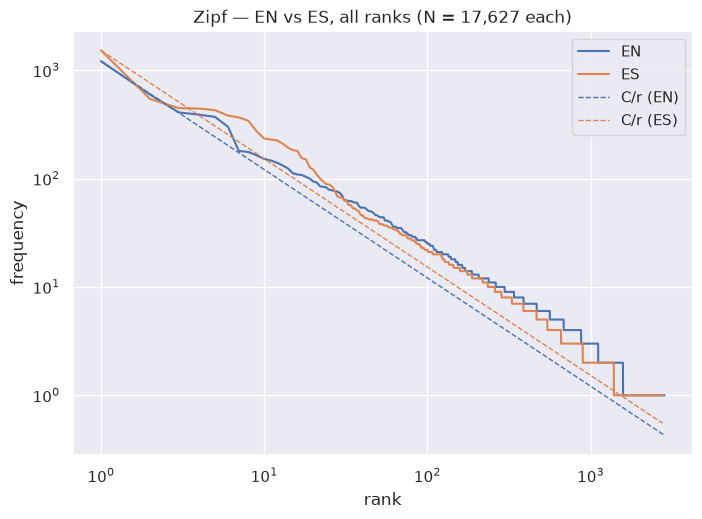

In [10]:
df = pd.concat(tables[(lang, "trunc")].assign(lang=lang.upper()) for lang in CORPORA)
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.lineplot(data=df, x="rank", y="f", hue="lang", ax=ax)
for i, lang in enumerate(CORPORA):
    t = tables[(lang, "trunc")]
    ax.plot(t["rank"], t["f"].iloc[0] / t["rank"], ls="--", lw=1, color=f"C{i}", label=f"C/r ({lang.upper()})")
ax.set(
    xscale="log", yscale="log", xlabel="rank", ylabel="frequency", title=f"Zipf — EN vs ES, all ranks (N = {N:,} each)"
)
ax.legend()
fig.savefig(PLOTS_DIR / "zipf_en_es.png", dpi=150, bbox_inches="tight")

## Step 9 — Values for the docx table

| docx column | What is computed |
|---|---|
| Corpus source | Title, author, institution, year (corpora table above) |
| Corpus dimension | Tokens N = `counts.total()`, types V = `len(counts)` |
| Zipf graphic (top 200 words) | `plots/zipf_top200_<lang>.png` |
| The 7 most frequent words (in order) | `counts.most_common(7)` |
| % of tokens covered by the 7 most frequent words, excluding stop words | Top 7 words not in the spaCy stop list; sum of their frequencies / N |
| % covered by words that appear once, as types | hapaxes / V × 100 |
| % covered by words that appear once, as tokens | hapaxes / N × 100 |

The "7 most frequent words" column does not say whether stop words count. With them, the list is all function words, so both versions are shown (`top7`, `top7_nostop`); the instructor decides which goes in the docx.

All values are computed for 4 cases: EN/ES × full/truncated. **The docx gets the truncated values** (both corpora at size N), with the original size noted in "Corpus dimension".

In [11]:
def metrics(counts: Counter, stop_words: set[str]) -> dict:
    tokens, types = counts.total(), len(counts)
    top7 = counts.most_common(7)
    top7_nostop = [(w, f) for w, f in counts.most_common() if w not in stop_words][:7]
    hapax = sum(1 for f in counts.values() if f == 1)
    s, _, r2 = fit_zipf([f for _, f in counts.most_common(200)])
    return {
        "tokens": tokens,
        "types": types,
        "top7": ", ".join(w for w, _ in top7),
        "cover7_%": round(100 * sum(f for _, f in top7) / tokens, 2),
        "top7_nostop": ", ".join(w for w, _ in top7_nostop),
        "cover7_nostop_%": round(100 * sum(f for _, f in top7_nostop) / tokens, 2),
        "hapax": hapax,
        "hapax_types_%": round(100 * hapax / types, 2),
        "hapax_tokens_%": round(100 * hapax / tokens, 2),
        "s": round(s, 3),
        "r2": round(r2, 3),
    }

results = pd.DataFrame({
    f"{lang} {version}": metrics(counts[(lang, version)], stops[lang])
    for lang in CORPORA for version in ("full", "trunc")
})
with pd.option_context("display.max_colwidth", None):
    display(results)

,en full,en trunc,es full,es trunc
tokens,17627,17627,24218,17627
types,2839,2839,3161,2765
top7,"the, of, to, and, a, in, or","the, of, to, and, a, in, or","de, la, que, en, el, y, se","de, la, que, en, el, y, los"
cover7_%,19.62,19.62,23.61,23.47
top7_nostop,"url, features, class, urls, number, classification, user","url, features, class, urls, number, classification, user","urls, datos, url, modelo, detección, web, clasificación","urls, url, web, datos, clasificación, aprendizaje, detección"
cover7_nostop_%,3.94,3.94,3.25,3.29
hapax,1261,1261,1500,1378
hapax_types_%,44.42,44.42,47.45,49.84
hapax_tokens_%,7.15,7.15,6.19,7.82
s,0.849,0.849,0.953,0.957


In [12]:
top7_df = pd.concat({
    (f"{lang} {version}", kind): pd.DataFrame(pairs, columns=["word", "f"], index=range(1, 8))
    for lang in CORPORA for version in ("full", "trunc")
    for kind, pairs in (
        ("top7", counts[(lang, version)].most_common(7)),
        ("top7_nostop", [(w, f) for w, f in counts[(lang, version)].most_common()
                         if w not in stops[lang]][:7]),
    )
}, axis=1).rename_axis("rank")

display(top7_df[["en trunc", "es trunc"]])  # docx values; full table in top7_df

en trunc                            es trunc                          
         top7           top7_nostop          top7          top7_nostop     
         word     f            word    f     word     f           word    f
rank                                                                       
1         the  1213             url  152       de  1527           urls  127
2          of   596        features  112       la   543            url   94
3          to   408           class  108      que   447            web   85
4         and   389            urls   92       en   443          datos   78
5           a   371          number   83       el   428  clasificación   67
6          in   301  classification   78        y   382    aprendizaje   67
7          or   180            user   70      los   367      detección   62

## Full vs truncated: what to expect

Only the larger corpus (Spanish) changes. Truncation lowers its token and type counts. Hapax shares usually rise slightly: in a shorter text, more words have so far appeared only once.

Top-7 coverage and the slope s should change only a little if the text is homogeneous. A large change would mean the dropped part (the last chapters) differs in style or topic.

--- en


,full,trunc,diff
tokens,17627.000,17627.000,0.0
types,2839.000,2839.000,0.0
cover7_%,19.620,19.620,0.0
cover7_nostop_%,3.940,3.940,0.0
hapax,1261.000,1261.000,0.0
hapax_types_%,44.420,44.420,0.0
hapax_tokens_%,7.150,7.150,0.0
s,0.849,0.849,0.0
r2,0.996,0.996,0.0


--- es


,full,trunc,diff
tokens,24218.000,17627.000,-6591.000
types,3161.000,2765.000,-396.000
cover7_%,23.610,23.470,-0.140
cover7_nostop_%,3.250,3.290,0.040
hapax,1500.000,1378.000,-122.000
hapax_types_%,47.450,49.840,2.390
hapax_tokens_%,6.190,7.820,1.630
s,0.953,0.957,0.004
r2,0.989,0.989,0.000


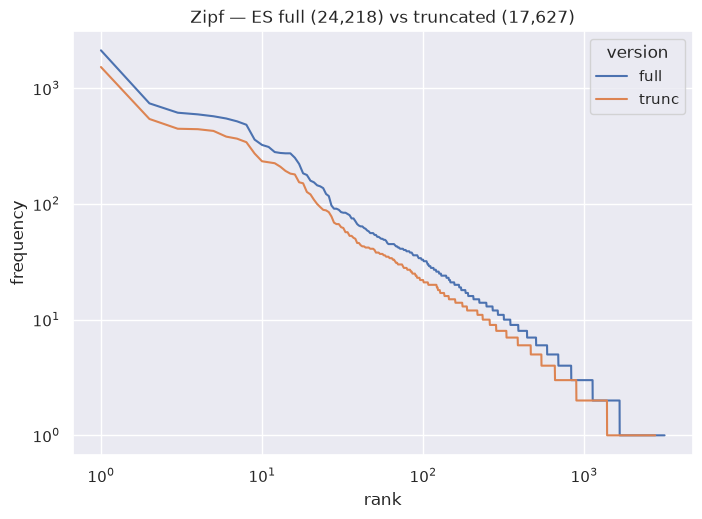

In [13]:
NUMERIC = ["tokens", "types", "cover7_%", "cover7_nostop_%", "hapax",
           "hapax_types_%", "hapax_tokens_%", "s", "r2"]
for lang in CORPORA:
    cmp = results[[f"{lang} full", f"{lang} trunc"]].loc[NUMERIC].astype(float)
    cmp.columns = ["full", "trunc"]
    cmp["diff"] = (cmp["trunc"] - cmp["full"]).round(3)
    print(f"--- {lang}")
    display(cmp)

big = max(CORPORA, key=lambda lang: len(words_full[lang]))
df = pd.concat(tables[(big, v)].assign(version=v) for v in ("full", "trunc"))
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.lineplot(data=df, x="rank", y="f", hue="version", ax=ax)
ax.set(xscale="log", yscale="log", xlabel="rank", ylabel="frequency",
       title=f"Zipf — {big.upper()} full ({len(words_full[big]):,}) vs truncated ({N:,})")
fig.savefig(PLOTS_DIR / "zipf_full_vs_trunc.png", dpi=150, bbox_inches="tight")

## Step 8 — Lemmas

Spanish inflects more than English (verb conjugation, gender and number agreement on articles and adjectives), so one lemma has more word forms. Counting lemmas (`token.lemma_`) instead of forms shows how much of the EN/ES difference comes from morphology: if Spanish loses more types than English when forms are merged, the extra Spanish types were inflection.

The same steps as for forms are repeated on the truncated corpora: rank–frequency table, fit, and plot.

--- en lemmas (truncated)


,rank,word,f,rel_f,r_f
0,1,the,1213,0.068815,1213
1,2,of,596,0.033812,1192
2,3,be,489,0.027742,1467
3,4,to,408,0.023146,1632
4,5,and,389,0.022068,1945
5,6,a,371,0.021047,2226
6,7,in,301,0.017076,2107
7,8,url,242,0.013729,1936
8,9,or,180,0.010212,1620
9,10,for,176,0.009985,1760


--- es lemmas (truncated)


,rank,word,f,rel_f,r_f
0,1,de,1527,0.086628,1527
1,2,el,1520,0.086231,3040
2,3,uno,510,0.028933,1530
3,4,él,471,0.026720,1884
4,5,que,447,0.025359,2235
5,6,en,443,0.025132,2658
6,7,y,382,0.021671,2674
7,8,ser,371,0.021047,2968
8,9,este,239,0.013559,2151
9,10,a,229,0.012991,2290


types  hapax_types_%  s_top200  r2_top200  s_all  r2_all
en forms   2839.0          44.42     0.849      0.996  1.032   0.966
   lemmas  2247.0          38.99     0.839      0.996  1.112   0.960
es forms   2765.0          49.84     0.957      0.989  1.020   0.972
   lemmas  2047.0          44.36     0.936      0.990  1.125   0.974

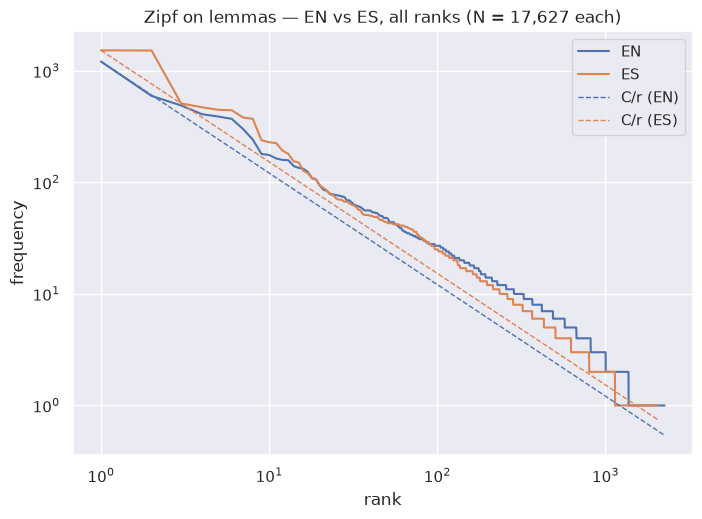

In [14]:
lemma_counts = {lang: Counter(lemmas_trunc[lang]) for lang in CORPORA}
lemma_tables = {lang: rank_table(c) for lang, c in lemma_counts.items()}
for lang in CORPORA:
    print(f"--- {lang} lemmas (truncated)")
    display(lemma_tables[lang].head(20))

rows = {}
for lang in CORPORA:
    for unit, c in (("forms", counts[(lang, "trunc")]), ("lemmas", lemma_counts[lang])):
        freqs = [f for _, f in c.most_common()]
        s200, _, r2_200 = fit_zipf(freqs[:200])
        s_all, _, r2_all = fit_zipf(freqs)
        hapax = sum(1 for f in c.values() if f == 1)
        rows[(lang, unit)] = {
            "types": len(c),
            "hapax_types_%": round(100 * hapax / len(c), 2),
            "s_top200": round(s200, 3), "r2_top200": round(r2_200, 3),
            "s_all": round(s_all, 3), "r2_all": round(r2_all, 3),
        }
forms_vs_lemmas = pd.DataFrame(rows).T
display(forms_vs_lemmas)

df = pd.concat(lemma_tables[lang].assign(lang=lang.upper()) for lang in CORPORA)
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.lineplot(data=df, x="rank", y="f", hue="lang", ax=ax)
for i, lang in enumerate(CORPORA):
    t = lemma_tables[lang]
    ax.plot(t["rank"], t["f"].iloc[0] / t["rank"], ls="--", lw=1, color=f"C{i}",
            label=f"C/r ({lang.upper()})")
ax.set(xscale="log", yscale="log", xlabel="rank", ylabel="frequency",
       title=f"Zipf on lemmas — EN vs ES, all ranks (N = {N:,} each)")
ax.legend()
fig.savefig(PLOTS_DIR / "zipf_lemmas_en_es.png", dpi=150, bbox_inches="tight")

## Observations

All values below are for the truncated corpora (N = 17,627 tokens each) unless stated otherwise.

**How well Zipf's law holds.** Both corpora follow it closely. On the top 200 words the fit is very good: EN s = 0.849, R² = 0.996; ES s = 0.957, R² = 0.989. On all ranks, s is close to 1 in both (EN 1.032, ES 1.020), with slightly lower R² (0.966 / 0.972). The fit is weaker on all ranks because of the two expected deviations:
- **Head:** the first ranks lie off the line. In English, ranks 2–6 (*of, to, and, a, in*: 596–301 occurrences) form a flat step below *the* (1,213). In Spanish, *de* (1,527) is far ahead of *la* (543), so rank 2 falls below the line and ranks 4–8 rise above it. This is why the top-200 slope is flatter than 1, especially for English.
- **Tail:** about half of the types occur once, so the curves end in a long horizontal staircase (f = 1, 2, 3...), clearly visible in `zipf_en_es.png`.

**English vs Spanish (same N).**

| | EN | ES |
|---|---|---|
| Types | 2,839 | 2,765 |
| Hapax / types | 44.42% | 49.84% |
| Hapax / tokens | 7.15% | 7.82% |
| Top-7 coverage, with stop words | 19.62% | 23.47% |
| Top-7 coverage, without stop words | 3.94% | 3.29% |
| s (top 200) | 0.849 | 0.957 |

- Contrary to the expectation that Spanish has more types, the Spanish corpus has slightly *fewer* types (−74). It does have the expected higher hapax share: its vocabulary has a longer tail of words seen once.
- A likely reason for the lower type count: Spanish spends more tokens on function words. The top 7 (*de, la, que, en, el, y, los*) cover 23.5% of the Spanish text against 19.6% for English, leaving fewer tokens for content words. The English thesis also contains code identifiers and class names (*lgbmclassifier, randomforestclassifier, str, int*) that add types.
- **Lemmas:** merging forms removes 20.9% of English types (2,839 → 2,247) and 26.0% of Spanish types (2,765 → 2,047). Spanish loses more, which confirms its richer inflection: *el / la / los / las* all become *el* (1,520 together, almost as many as *de*), *un / una* become *uno*, verb forms become *ser*, *hacer*. With lemmas, s on all ranks rises to 1.11–1.13 in both languages, because the head grows while the tail shrinks.

**Full vs truncated (Spanish).** Truncating from 24,218 to 17,627 tokens (−27.2%) lowers the types from 3,161 to 2,765 and the hapaxes from 1,500 to 1,378. The hapax shares rise (types +2.39 points, tokens +1.63 points), as expected for a shorter text. The slope barely changes (0.953 → 0.957) and the top-7 coverage moves by less than 0.2 points, so the dropped final chapters are similar in style to the rest of the thesis.

**Most frequent words.** With stop words, the top 7 are only function words in both languages (*the, of, to, and, a, in, or* / *de, la, que, en, el, y, los*). Without stop words, the domain is obvious: *url, features, class, urls, number, classification, user* / *urls, url, web, datos, clasificación, aprendizaje, detección*. *url* and *urls* appear in both lists and cover about 1.4% (EN) and 1.2% (ES) of the text on their own. The English list leans towards the machine learning setup (features, class, classification), while the Spanish one names the general field (datos, aprendizaje, detección).

## Comparison with colleagues

*To fill in once the docx table has other rows.*

Compare against colleagues' corpora (other domains, genres or languages), at a similar size if possible:
- number of types for the same number of tokens (lexical variety);
- hapax shares (as types and as tokens);
- top-7 coverage with and without stop words;
- the shape of the Zipf plot and the slope s.

Expectation to check: technical text repeats a small set of domain terms, so it should have fewer types, a lower hapax share and higher coverage by its top content words than literary or news text. The function-word top 7 should look similar across corpora of the same language, whatever the genre.

| Colleague / corpus | Language, genre | Tokens | Types | Hapax / types | Top-7 coverage | Notes |
|---|---|---|---|---|---|---|
| | | | | | | |

## Limitations

- The English corpus is below the suggested 50k words (17,627 tokens after cleaning). Both corpora are truncated to this size, so the Spanish thesis loses 27.2% of its text (its last chapters).
- Cleaning is line-based: text from tables, figure captions and code listings still gets through (e.g. *lgbmclassifier, str, int* in English).
- spaCy's stop lists differ in size (326 English vs 521 Spanish), which affects the "excluding stop words" values.
- The small spaCy models make lemma errors: Spanish *se* is lemmatized as *él*, and *urls* is not merged with *url* in Spanish (it is in English).
- The English thesis was written by the analyst (originality approved by the instructor).